<a href="https://colab.research.google.com/github/Ranjitkumarmuduli/tomato-disease-detection/blob/main/01_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data set for Tomato Crop

AI-Based Tomato Leaf Disease Detection and Treatment Recommendation.

**Goal:** Download PlantVillage, keep only the tomato classes, remove duplicates,
and split the data into train (70%), validation (15%) and test (15%) sets.

## 1. Install libraries
`kagglehub` downloads datasets from Kaggle


In [1]:
# Install the Kaggle download helper (-q = quiet, hides long install logs)
!pip -q install kagglehub

## 2. Import libraries
- `os`: work with folders and files
- `hashlib`: create a unique fingerprint (MD5) of each image to find duplicates
- `pandas`: store the image list as a table
- `matplotlib`: draw charts
- `train_test_split`: split the data while keeping class proportions

In [2]:
import os                      # folder and file handling
import hashlib                 # MD5 fingerprints for duplicate detection
import kagglehub               # Kaggle dataset download
import pandas as pd            # tables (DataFrames)
import matplotlib.pyplot as plt  # charts
from sklearn.model_selection import train_test_split  # stratified splitting

print("Libraries imported successfully")

Libraries imported successfully


## 3. Connect Google Drive
All results are saved to Google Drive.
Project folder: `MyDrive/tomato_project/`
- `splits/`: train / val / test lists
- `weights/`: trained models
- `results/`: metrics and reports
- `figures/`: charts for the thesis

In [5]:
#Mounting the GDrive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
#Project folder path
PROJ = "/content/drive/MyDrive/tomato_project"


# Create the sub-folders
for folder in ["splits", "weights", "results", "figures"]:
    os.makedirs(f"{PROJ}/{folder}", exist_ok=True)

print("Project folders ready in:", PROJ)

Project folders ready in: /content/drive/MyDrive/tomato_project


## 4. Download PlantVillage
Source: Kaggle – `abdallahalidev/plantvillage-dataset` (~2 GB, 38 classes, 14 crops).
We use the **color** version (original RGB photos).

In [8]:
# Download the dataset
base = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

# Path to the folder that holds one sub-folder per class
ROOT = f"{base}/plantvillage dataset/color"

print("Dataset location:", ROOT)
print("Total classes in PlantVillage:", len(os.listdir(ROOT)))

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset location: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Total classes in PlantVillage: 38


## 5. Select tomato classes
We keep those 10 classes (9 diseases + healthy)
and build a table with one row per image: its path, a numeric label, and the class name.

In [9]:
# Keeping only the folders whose name starts with "Tomato___"
classes = sorted(c for c in os.listdir(ROOT) if c.startswith("Tomato___"))

# Short readable names
names = [c.replace("Tomato___", "") for c in classes]

# One row per image: relative path, numeric label (0-9), class name
rows = []
for label, folder in enumerate(classes):
    for file in sorted(os.listdir(f"{ROOT}/{folder}")):
        rows.append({"relpath": f"{folder}/{file}", "label": label, "class": names[label]})
df = pd.DataFrame(rows)

print("Tomato classes:", len(classes))
print("Tomato images :", len(df))
df.head()

Tomato classes: 10
Tomato images : 18160


,relpath,label,class
0,Tomato___Bacterial_spot/00416648-be6e-4bd4-bc8...,0,Bacterial_spot
1,Tomato___Bacterial_spot/0045ba29-ed1b-43b4-afd...,0,Bacterial_spot
2,Tomato___Bacterial_spot/00639d29-2d1a-4fcf-9bd...,0,Bacterial_spot
3,Tomato___Bacterial_spot/00728f4d-83a0-49f1-87f...,0,Bacterial_spot
4,Tomato___Bacterial_spot/00a7c269-3476-4d25-b74...,0,Bacterial_spot


## 6. Data Cleaning: Remove duplicate images
If the same photo appears twice, one copy could land in training and the other in testing.
That would make the test score look better than it really is (**data leakage**).
We compute an MD5 fingerprint for every file; identical files have identical fingerprints.

In [10]:
# Compute the MD5 fingerprint of each image file
df["md5"] = [hashlib.md5(open(f"{ROOT}/{p}", "rb").read()).hexdigest() for p in df.relpath]

n_dup = df.duplicated("md5").sum()          # number of extra copies
df = df.drop_duplicates("md5").reset_index(drop=True)   # keep one copy of each

print("Duplicates removed:", n_dup)
print("Images after cleaning:", len(df))

Duplicates removed: 14
Images after cleaning: 18146


## 7. Stratified split
- **Train (70%)**: the model learns from these images
- **Validation (15%)**: used during training to pick the best model
- **Test (15%)**: used only once at the end, for the final score in the thesis


In [11]:
# First split: 70% train
train, temp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)

# Second split: the rest 30% becomes 15% validation + 15% test
val, test = train_test_split(temp, test_size=0.50, stratify=temp.label, random_state=42)

print(f"Train: {len(train):,} | Validation: {len(val):,} | Test: {len(test):,}")

Train: 12,702 | Validation: 2,722 | Test: 2,722


## 8. Save the splits
The CSV files are saved to Drive


In [12]:
# Save each split as a CSV file (path, label, class name)
for name, part in [("train", train), ("val", val), ("test", test)]:
    part[["relpath", "label", "class"]].to_csv(f"{PROJ}/splits/{name}.csv", index=False)

# Save the class names in label order (0 to 9)
pd.Series(names).to_csv(f"{PROJ}/splits/classes.csv", index=False, header=False)

print("Saved files:", os.listdir(f"{PROJ}/splits"))

Saved files: ['train.csv', 'val.csv', 'test.csv', 'classes.csv']


## 9. Images per class


In [14]:
counts = df["class"].value_counts()
print(counts.to_string())
print(f"\nLargest / smallest class ratio: {counts.max() / counts.min():.1f} : 1")

class
Tomato_Yellow_Leaf_Curl_Virus           5357
Bacterial_spot                          2127
Late_blight                             1901
Septoria_leaf_spot                      1771
Spider_mites Two-spotted_spider_mite    1676
healthy                                 1585
Target_Spot                             1404
Early_blight                            1000
Leaf_Mold                                952
Tomato_mosaic_virus                      373

Largest / smallest class ratio: 14.4 : 1


## 10. Class distribution chart
Saved to `figures/class_distribution.png` at 300 dpi (print quality) for the thesis.

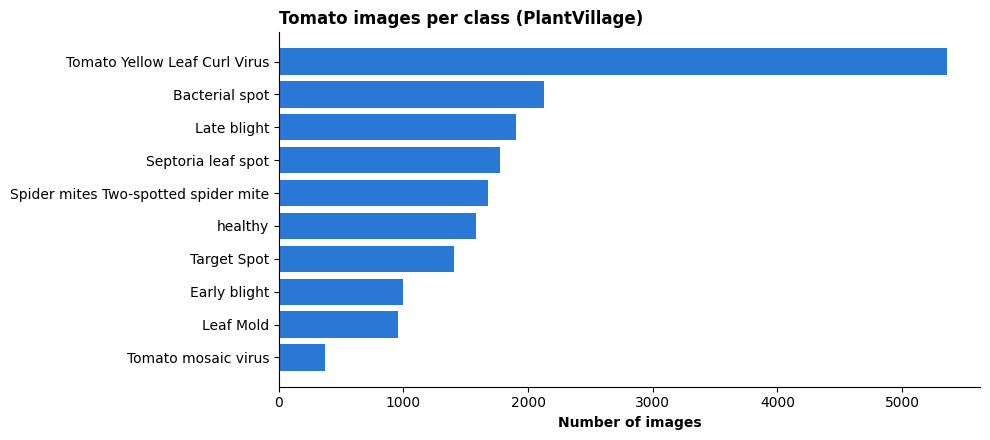

In [21]:
counts = df["class"].value_counts().sort_values()   # smallest at the bottom

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(counts.index.str.replace("_", " "), counts.values, color="#2a78d6")
ax.set_xlabel("Number of images", fontweight="bold")
ax.set_title("Tomato images per class (PlantVillage)", loc="Left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)      # cleaner look

plt.tight_layout()
plt.savefig(f"{PROJ}/figures/class_distribution.png", dpi=300)
plt.show()